<a href="https://colab.research.google.com/github/Prateek-Dhar-Dwivedi/NLP_Practical_2026_Colab_Files/blob/main/Practical_5_SmartSpam_Naive_Bayes_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 5: SmartSpam — Text Classification with Naive Bayes & Logistic Regression
**Module 2 · Intermediate Level**

## Project
Build a complete spam-message detector in this single Google Colab notebook. You'll prepare text, split data without leakage, train **Multinomial Naive Bayes** and **Logistic Regression**, compare metrics, inspect important words, and classify new messages.

### Learning objectives
- Train and evaluate two classical text classifiers.
- Understand bag-of-words / TF-IDF features and model assumptions.
- Compare accuracy, precision, recall, F1-score, and confusion matrices.
- Predict whether new messages are **spam** or **ham** (legitimate).
- Avoid data leakage by fitting text vectorization on training data only.

**Dataset:** UCI SMS Spam Collection (downloaded automatically).  
**Runtime:** Google Colab · Python · scikit-learn · pandas · matplotlib/seaborn.

> Run the cells from top to bottom. No API key, backend, or separate project files are required.

## 1. Import libraries

In [1]:
import io, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=UserWarning)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load the SMS Spam Collection dataset
The dataset contains real SMS messages labeled as spam or ham. This cell downloads and extracts the public UCI dataset.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

try:
    with urllib.request.urlopen(DATA_URL, timeout=30) as response:
        zip_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        data_file = next(name for name in zf.namelist() if name.endswith("SMSSpamCollection"))
        raw = pd.read_csv(
            zf.open(data_file), sep="\t", header=None,
            names=["label", "message"], encoding="utf-8"
        )
except Exception as exc:
    raise RuntimeError(
        "Dataset download failed. In Colab, check your internet connection and rerun this cell."
    ) from exc

raw = raw.dropna(subset=["label", "message"]).drop_duplicates().reset_index(drop=True)
raw["label"] = raw["label"].str.strip().str.lower()
raw = raw[raw["label"].isin(["ham", "spam"])].copy()

print(f"Dataset shape: {raw.shape[0]:,} messages")
display(raw.head(10))
print("\nLabel counts:")
display(raw["label"].value_counts().to_frame("count"))

Dataset shape: 5,169 messages


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...



Label counts:


,count
label,
ham,4516
spam,653


## 3. Explore the data
Check class balance and message length before training.

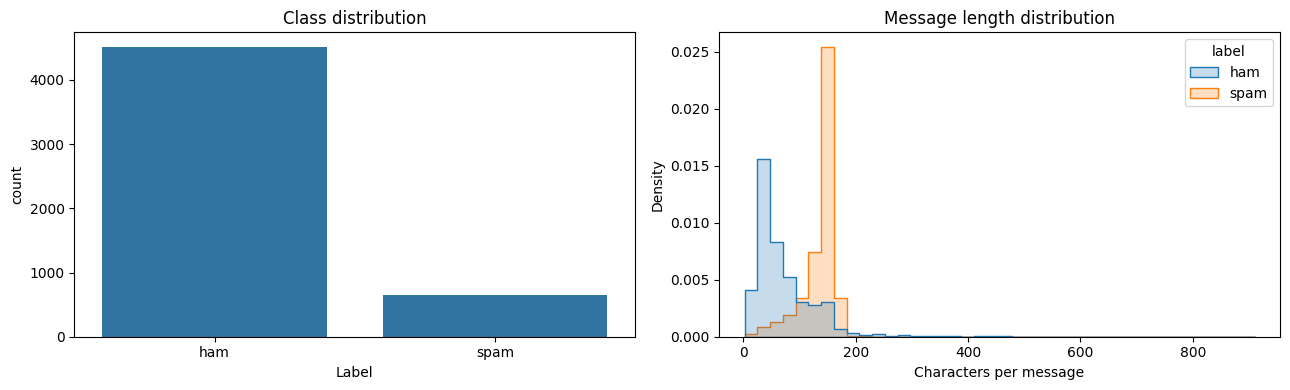

Spam proportion: 12.63%
Note: class imbalance makes accuracy alone an incomplete metric.


In [3]:
raw["message_length"] = raw["message"].str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=raw, x="label", order=["ham", "spam"], ax=axes[0])
axes[0].set_title("Class distribution")
axes[0].set_xlabel("Label")
sns.histplot(
    data=raw, x="message_length", hue="label", bins=40,
    element="step", stat="density", common_norm=False, ax=axes[1]
)
axes[1].set_title("Message length distribution")
axes[1].set_xlabel("Characters per message")
plt.tight_layout()
plt.show()

print("Spam proportion: {:.2%}".format((raw["label"] == "spam").mean()))
print("Note: class imbalance makes accuracy alone an incomplete metric.")

## 4. Create a train/test split (avoid data leakage)

We split first, then let each model's **Pipeline** fit TF-IDF only on the training messages. If vocabulary or IDF weights are learned from the test set, information leaks into training and evaluation becomes overly optimistic.

- **Training set:** learns vocabulary, IDF weights, and classifier parameters.
- **Test set:** held back until final evaluation.
- **Stratification:** preserves roughly the same spam/ham proportions in both sets.

In [4]:
X = raw["message"].astype(str)
y = raw["label"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training messages: {len(X_train):,}")
print(f"Test messages:     {len(X_test):,}")
print("\nTraining label proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("Test label proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Training messages: 4,135
Test messages:     1,034

Training label proportions:


,proportion
label,
ham,0.873761
spam,0.126239


Test label proportions:


,proportion
label,
ham,0.873308
spam,0.126692


## 5. Build and train both classifiers
We use the same TF-IDF text representation for a fair comparison. Multinomial Naive Bayes models class-conditional word-feature likelihoods; Logistic Regression learns class probabilities from a linear decision boundary.

In [5]:
models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True, stop_words="english",
            ngram_range=(1, 2), min_df=2, sublinear_tf=True
        )),
        ("classifier", MultinomialNB(alpha=0.5))
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True, stop_words="english",
            ngram_range=(1, 2), min_df=2, sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=2000, class_weight=None, random_state=RANDOM_STATE
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

print("\nImportant: TF-IDF was fitted inside each pipeline using X_train only.")

Trained: Multinomial Naive Bayes
Trained: Logistic Regression

Important: TF-IDF was fitted inside each pipeline using X_train only.


## 6. Evaluate and compare
Precision answers “when the model predicts spam, how often is it correct?” Recall answers “how much of all spam does it catch?” F1 balances precision and recall.

,Accuracy,Spam Precision,Spam Recall,Spam F1,Ham Precision,Ham Recall,Ham F1
Model,,,,,,,
Multinomial Naive Bayes,0.978,1.000,0.824,0.904,0.975,1.000,0.987
Logistic Regression,0.956,0.978,0.672,0.796,0.954,0.998,0.976


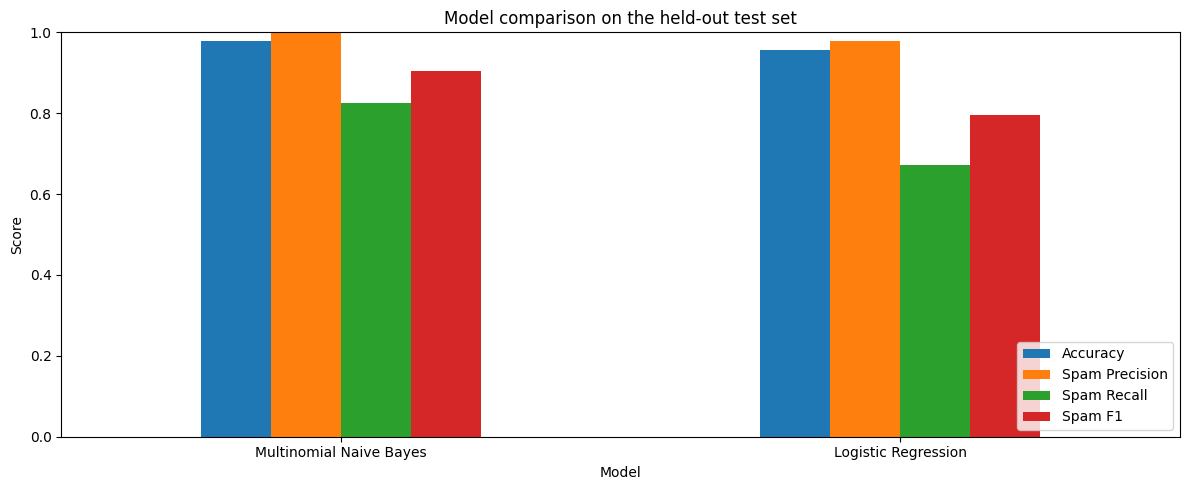

In [6]:
results = []
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Spam Precision": precision_score(y_test, pred, pos_label="spam", zero_division=0),
        "Spam Recall": recall_score(y_test, pred, pos_label="spam", zero_division=0),
        "Spam F1": f1_score(y_test, pred, pos_label="spam", zero_division=0),
        "Ham Precision": precision_score(y_test, pred, pos_label="ham", zero_division=0),
        "Ham Recall": recall_score(y_test, pred, pos_label="ham", zero_division=0),
        "Ham F1": f1_score(y_test, pred, pos_label="ham", zero_division=0),
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("Spam F1", ascending=False)
display(results_df.style.format("{:.3f}"))

ax = results_df[["Accuracy", "Spam Precision", "Spam Recall", "Spam F1"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1), rot=0
)
ax.set_title("Model comparison on the held-out test set")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Confusion matrices and classification reports
Rows are actual labels; columns are predicted labels. A spam message predicted as ham is a false negative; a legitimate ham message predicted as spam is a false positive.

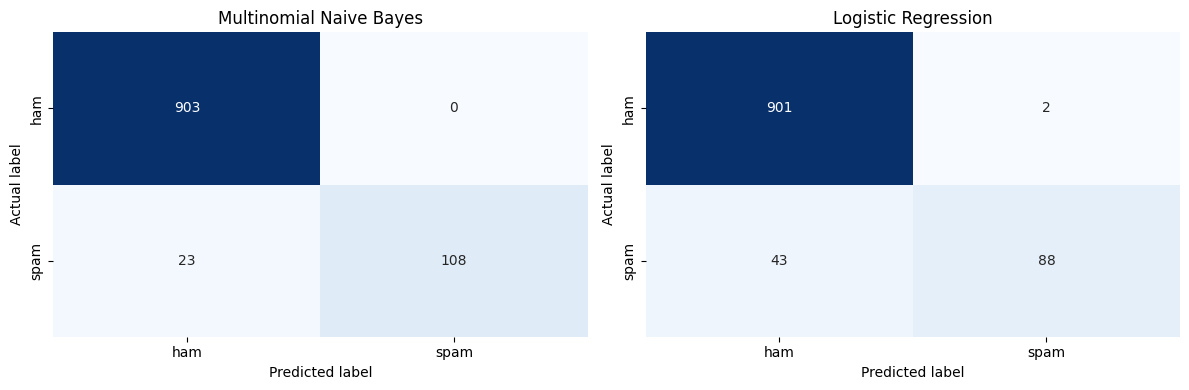

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       1.00      0.82      0.90       131

    accuracy                           0.98      1034
   macro avg       0.99      0.91      0.95      1034
weighted avg       0.98      0.98      0.98      1034

Logistic Regression
              precision    recall  f1-score   support

         ham       0.95      1.00      0.98       903
        spam       0.98      0.67      0.80       131

    accuracy                           0.96      1034
   macro avg       0.97      0.83      0.89      1034
weighted avg       0.96      0.96      0.95      1034



In [7]:
fig, axes = plt.subplots(1, len(models), figsize=(12, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, predictions[name], labels=["ham", "spam"])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["ham", "spam"], yticklabels=["ham", "spam"]
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.tight_layout()
plt.show()

for name in models:
    print("=" * 72)
    print(name)
    print(classification_report(
        y_test, predictions[name], labels=["ham", "spam"], zero_division=0
    ))

## 8. Cross-validation on the training set
Cross-validation estimates how consistently each full pipeline performs across several stratified folds. The test set remains untouched during this step.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    cv_rows.append({
        "Model": name,
        "Mean macro F1": scores.mean(),
        "Std. deviation": scores.std(),
        "Fold scores": np.round(scores, 3).tolist()
    })

cv_df = pd.DataFrame(cv_rows).set_index("Model")
display(cv_df)
print("Macro F1 gives equal weight to ham and spam F1, which is useful for imbalanced labels.")

,Mean macro F1,Std. deviation,Fold scores
Model,,,
Multinomial Naive Bayes,0.946949,0.006001,"[0.946, 0.95, 0.944, 0.956, 0.938]"
Logistic Regression,0.876276,0.013840,"[0.866, 0.877, 0.902, 0.874, 0.862]"


Macro F1 gives equal weight to ham and spam F1, which is useful for imbalanced labels.


## 9. Understand what the models learned
Inspect words and phrases associated with spam. For Naive Bayes, we show the largest class-conditional feature log-probabilities; for Logistic Regression, positive spam coefficients indicate features that push predictions toward spam. These are associations, not proof of causation.

In [9]:
def top_features_for_model(model, model_name, n=15):
    vectorizer = model.named_steps["tfidf"]
    classifier = model.named_steps["classifier"]
    features = np.array(vectorizer.get_feature_names_out())
    spam_index = list(classifier.classes_).index("spam")

    if model_name == "Multinomial Naive Bayes":
        values = classifier.feature_log_prob_[spam_index]
        # Compare spam likelihood with ham likelihood to find distinctive terms.
        ham_index = list(classifier.classes_).index("ham")
        values = classifier.feature_log_prob_[spam_index] - classifier.feature_log_prob_[ham_index]
    else:
        values = classifier.coef_[0]

    top_ids = np.argsort(values)[-n:][::-1]
    return pd.DataFrame({"Feature": features[top_ids], "Spam association score": values[top_ids]})

for name, model in models.items():
    print("\n", name)
    display(top_features_for_model(model, name))


 Multinomial Naive Bayes


,Feature,Spam association score
0,claim,3.983504
1,prize,3.898013
2,www,3.697705
3,150p,3.530878
4,uk,3.509544
5,18,3.453555
6,guaranteed,3.307481
7,1000,3.301989
8,500,3.258540
9,tone,3.233417



 Logistic Regression


,Feature,Spam association score
0,txt,4.062858
1,mobile,3.672141
2,www,3.309924
3,uk,3.303814
4,claim,3.171702
5,reply,3.109429
6,free,3.076612
7,text,2.935226
8,stop,2.728821
9,prize,2.626136


## 10. Predict unseen messages
Edit the examples or add your own messages. Predictions are model outputs, not guarantees; review borderline or high-impact decisions.

In [10]:
new_messages = [
    "Congratulations! You have won a free prize. Call now to claim your reward!",
    "Hey, are we still meeting at the library at 3 pm?",
    "URGENT! Your account has been selected for a cash reward. Click this link now.",
    "Can you send me the notes from today's lecture?"
]

def predict_messages(messages, model=models["Logistic Regression"]):
    labels = model.predict(messages)
    probabilities = model.predict_proba(messages)
    classes = list(model.named_steps["classifier"].classes_)
    spam_col = classes.index("spam")
    return pd.DataFrame({
        "Message": messages,
        "Prediction": labels,
        "Spam probability": probabilities[:, spam_col].round(3),
        "Interpretation": [
            "Likely spam" if label == "spam" else "Likely legitimate (ham)"
            for label in labels
        ]
    })

display(predict_messages(new_messages))
print("Default demo model: Logistic Regression")

,Message,Prediction,Spam probability,Interpretation
0,Congratulations! You have won a free prize. Call now to claim your reward!,spam,0.815,Likely spam
1,"Hey, are we still meeting at the library at 3 pm?",ham,0.047,Likely legitimate (ham)
2,URGENT! Your account has been selected for a cash reward. Click this link now.,spam,0.564,Likely spam
3,Can you send me the notes from today's lecture?,ham,0.084,Likely legitimate (ham)


Default demo model: Logistic Regression


## 11. Interactive mini spam checker
Type a message below and run the cell to classify it with the trained Logistic Regression pipeline.

In [11]:
# Change this string and rerun the cell to test your own message.
my_message = "Your package delivery is delayed. Track it using the official app."
display(predict_messages([my_message]))

,Message,Prediction,Spam probability,Interpretation
0,Your package delivery is delayed. Track it using the official app.,ham,0.125,Likely legitimate (ham)


## 12. Algorithm assumptions and practical comparison

| Aspect | Multinomial Naive Bayes | Logistic Regression |
|---|---|---|
| Main idea | Applies Bayes' rule with class-conditional feature likelihoods | Learns a linear decision boundary and estimates class probabilities |
| Key assumption | Features are conditionally independent given the class (simplifying assumption) | Log-odds are linear in the input features |
| Strengths | Very fast, effective baseline, works well with sparse text | Often strong with TF-IDF; flexible regularization; interpretable coefficients |
| Limitations | Independence assumption is unrealistic; probabilities may be poorly calibrated | Needs optimization; linear boundary may miss complex patterns |
| Feature representation | Count features are classic; nonnegative TF-IDF also works | TF-IDF is a common strong baseline |

**Important:** Neither model “understands” messages like a human. They learn statistical patterns from labeled examples.

## 13. Final project summary
The next cell creates a concise summary you can use in a lab submission.

In [12]:
best_model_name = results_df["Spam F1"].idxmax()
best_spam_f1 = results_df.loc[best_model_name, "Spam F1"]
best_accuracy = results_df.loc[best_model_name, "Accuracy"]

print("PROJECT: SmartSpam — Classical SMS Spam Detection")
print(f"Dataset messages after cleaning: {len(raw):,}")
print(f"Training / test split: {len(X_train):,} / {len(X_test):,} (80/20, stratified)")
print("Models: Multinomial Naive Bayes and Logistic Regression")
print(f"Highest test spam F1: {best_model_name} ({best_spam_f1:.3f})")
print(f"That model's test accuracy: {best_accuracy:.3f}")
print("\nConclusion template:")
print(
    f"On this held-out test split, {best_model_name} achieved the highest spam F1 "
    f"among the two tested models. Model choice should consider spam recall and "
    f"false positives as well as accuracy. Results may vary with split, preprocessing, "
    f"and dataset version."
)

PROJECT: SmartSpam — Classical SMS Spam Detection
Dataset messages after cleaning: 5,169
Training / test split: 4,135 / 1,034 (80/20, stratified)
Models: Multinomial Naive Bayes and Logistic Regression
Highest test spam F1: Multinomial Naive Bayes (0.904)
That model's test accuracy: 0.978

Conclusion template:
On this held-out test split, Multinomial Naive Bayes achieved the highest spam F1 among the two tested models. Model choice should consider spam recall and false positives as well as accuracy. Results may vary with split, preprocessing, and dataset version.
